# Healthcare Survey: Income & Spending Analysis

Analysis of the survey responses collected by the Flask app and exported from MongoDB with `export_to_csv.py`. It answers two client questions, and the charts are exported as PNGs in `charts/` for the PowerPoint presentation:

1. **Which ages have the highest income?**
2. **How is spending in each category distributed across genders?**

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
DATA_FILE = Path("survey_data.csv")
CHART_DIR = Path("charts")
INCLUDE_SYNTHETIC = True          # Set to False to analyse real form submissions only

CATEGORIES = {"utilities": "Utilities", "entertainment": "Entertainment",
              "school_fees": "School fees", "shopping": "Shopping", "healthcare": "Healthcare"}
GENDER_ORDER = ["Female", "Male", "Non-binary", "Prefer not to say"]
GENDER_COLORS = {"Female": "#2a78d6", "Male": "#eb6834",            # Colour-blind-safe palette,
                 "Non-binary": "#1baf7a", "Prefer not to say": "#eda100"}   # fixed per gender
ACCENT, MUTED = "#2a78d6", "#c9ced6"
AGE_BINS = [18, 25, 35, 45, 55, 65, 101]
AGE_LABELS = ["18–24", "25–34", "35–44", "45–54", "55–64", "65+"]

# Slide-friendly (16:9) charts with a clean style
plt.rcParams.update({"figure.figsize": (10, 5.625), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 14})
CHART_DIR.mkdir(exist_ok=True)

## 1. Load and check the data

In [15]:
try:
    survey = pd.read_csv(DATA_FILE, parse_dates=["submitted_at"])
except FileNotFoundError:
    raise FileNotFoundError(f"{DATA_FILE} not found. Run `python export_to_csv.py` first.") from None

if not INCLUDE_SYNTHETIC:
    survey = survey[survey["source"] == "survey"]

survey["age_group"] = pd.cut(survey["age"], bins=AGE_BINS, labels=AGE_LABELS, right=False)
print(f"{len(survey)} responses | missing values: {survey.isna().sum().sum()}")
print(survey["source"].value_counts().to_string())
survey.head()

121 responses | missing values: 0
source
synthetic    120
survey         1


,age,gender,total_income,utilities,entertainment,school_fees,shopping,healthcare,total_expenses,submitted_at,source,age_group
0,56,Female,5110.0,422.84,0.00,0.00,297.35,346.25,1066.44,2026-10-18 16:36:24.098,synthetic,55–64
1,32,Male,2590.0,196.56,179.48,388.89,0.00,117.46,882.39,2026-10-18 18:18:47.713,synthetic,25–34
2,33,Male,5810.0,431.81,447.48,685.24,332.65,580.37,2477.55,2026-10-18 19:21:03.196,synthetic,25–34
3,43,Female,7470.0,812.84,461.93,887.38,0.00,493.18,2655.33,2026-10-19 01:05:40.184,synthetic,35–44
4,29,Male,3630.0,291.57,353.57,711.41,0.00,357.90,1714.45,2026-10-19 16:06:22.004,synthetic,25–34


In [16]:
survey[["age", "total_income", *CATEGORIES, "total_expenses"]].describe().round(1)

,age,total_income,utilities,entertainment,school_fees,shopping,healthcare,total_expenses
count,121.0,121.0,121.0,121.0,121.0,121.0,121.0,121.0
mean,39.6,5368.5,461.0,231.1,287.1,452.2,298.9,1730.2
std,13.0,2226.3,238.8,211.4,414.8,352.5,208.4,873.5
min,18.0,1420.0,0.0,0.0,0.0,0.0,0.0,227.4
25%,30.0,3490.0,287.8,0.0,0.0,207.8,150.4,1040.8
50%,38.0,5230.0,431.8,190.7,0.0,450.8,276.8,1620.8
75%,49.0,6730.0,597.0,362.2,566.5,663.8,463.9,2440.0
max,75.0,12190.0,1075.0,874.3,1497.4,1664.9,981.3,4550.9


In [17]:
survey["gender"].value_counts().reindex(GENDER_ORDER, fill_value=0).to_frame("participants")

,participants
gender,
Female,69
Male,45
Non-binary,5
Prefer not to say,2


In [18]:
def data_note(df):
    """Footnote for exported charts: response count, flagging synthetic sample data when present."""
    synthetic = (df["source"] == "synthetic").sum()
    note = f"Based on {len(df)} survey responses"
    return note + (f" ({synthetic} are synthetic sample data)." if synthetic else ".")


def export_chart(fig, name):
    """Save a chart as a high-resolution PNG for PowerPoint."""
    path = CHART_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    print(f"Exported {path}")

## 2. Which ages have the highest income?

Average monthly income for each age group. The highest-earning group is highlighted.

In [19]:
income_by_age = (survey.groupby("age_group", observed=False)["total_income"]
                  .agg(participants="count", average_income="mean", median_income="median")
                  .round(0))
top_group = income_by_age["average_income"].idxmax()
income_by_age

,participants,average_income,median_income
age_group,,,
18–24,18,2761.0,2840.0
25–34,33,4281.0,3860.0
35–44,25,6257.0,6110.0
45–54,28,7273.0,7230.0
55–64,13,6448.0,6170.0
65+,4,3675.0,3660.0


Exported charts/income_by_age_group.png


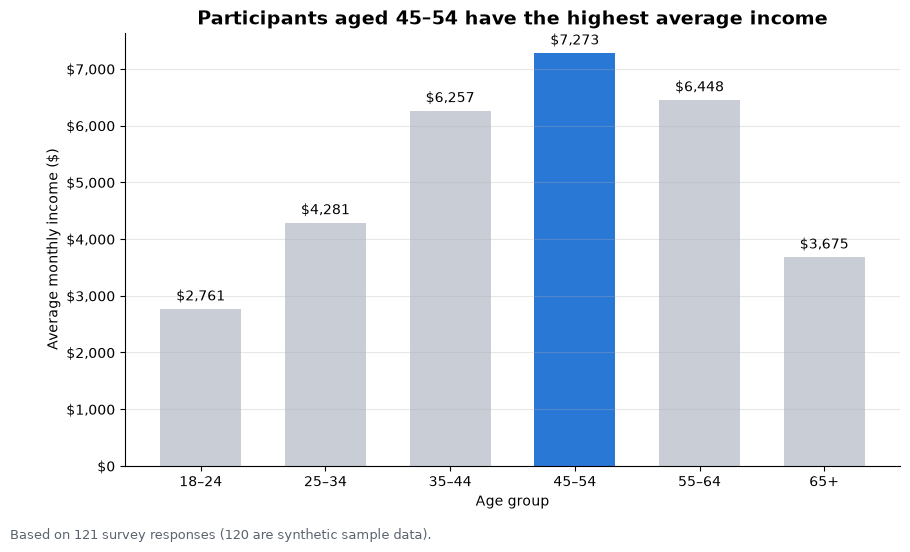

In [20]:
fig, ax = plt.subplots()
colors = [ACCENT if group == top_group else MUTED for group in income_by_age.index]
bars = ax.bar(income_by_age.index.astype(str), income_by_age["average_income"], color=colors, width=0.65)
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in income_by_age["average_income"]], padding=4, fontsize=10)
ax.set(title=f"Participants aged {top_group} have the highest average income",
       xlabel="Age group", ylabel="Average monthly income ($)")
ax.yaxis.set_major_formatter(lambda value, _: f"${value:,.0f}")
ax.grid(axis="y", alpha=0.3)
fig.text(0.01, -0.02, data_note(survey), fontsize=9, color="#5b636e")
export_chart(fig, "income_by_age_group")
plt.show()

The five individual ages with the highest average income. Ages with fewer than 3 participants are left out, so a single high earner doesn't skew the ranking:

In [21]:
(survey.groupby("age")["total_income"].agg(participants="count", average_income="mean")
       .query("participants >= 3")
       .sort_values("average_income", ascending=False)
       .head(5).round(0))

,participants,average_income
age,,
48,4,8515.0
47,3,7823.0
50,5,7718.0
43,5,7582.0
55,5,7478.0


## 3. How is spending distributed across genders?

**Share of each category's total spending, by gender.** This shows who accounts for the money spent in each category.

In [22]:
spending = survey.groupby("gender")[list(CATEGORIES)].sum().reindex(GENDER_ORDER).fillna(0)
spending_share = (spending / spending.sum() * 100).rename(columns=CATEGORIES)
spending_share.round(1)

,Utilities,Entertainment,School fees,Shopping,Healthcare
gender,,,,,
Female,58.2,51.9,61.2,58.6,53.4
Male,36.8,40.3,28.1,33.9,41.0
Non-binary,2.9,4.5,6.8,5.3,4.5
Prefer not to say,2.1,3.2,3.9,2.2,1.1


Exported charts/spending_share_by_gender.png


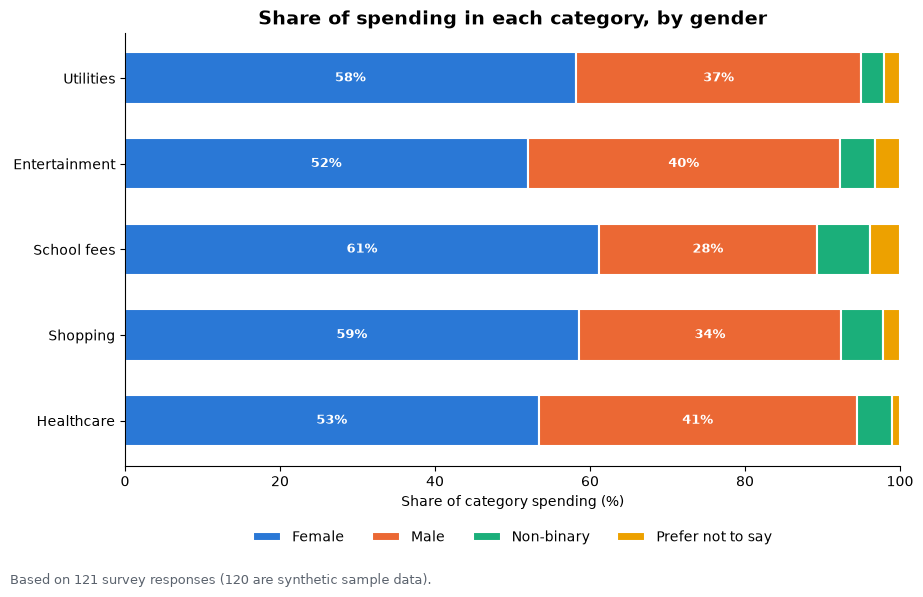

In [23]:
fig, ax = plt.subplots()
left = pd.Series(0.0, index=spending_share.columns)
for gender in GENDER_ORDER:
    values = spending_share.loc[gender]
    ax.barh(spending_share.columns, values, left=left, color=GENDER_COLORS[gender], label=gender,
            height=0.6, edgecolor="white", linewidth=1.5)
    for category, value in values.items():                     # Label segments wide enough to fit text
        if value >= 8:
            ax.text(left[category] + value / 2, category, f"{value:.0f}%",
                    ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += values
ax.set(title="Share of spending in each category, by gender", xlabel="Share of category spending (%)", xlim=(0, 100))
ax.invert_yaxis()
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
fig.text(0.01, -0.1, data_note(survey), fontsize=9, color="#5b636e")
export_chart(fig, "spending_share_by_gender")
plt.show()

**Average monthly spend per participant, by gender.** The genders differ greatly in group size, so the averages show whether a gender spends more *per person*, not just in total. Participants who don't spend on a category count as $0.

In [24]:
average_spend = survey.groupby("gender")[list(CATEGORIES)].mean().reindex(GENDER_ORDER).rename(columns=CATEGORIES)
group_sizes = survey["gender"].value_counts()
average_spend.round(0)

,Utilities,Entertainment,School fees,Shopping,Healthcare
gender,,,,,
Female,470.0,211.0,308.0,464.0,280.0
Male,457.0,251.0,217.0,412.0,330.0
Non-binary,323.0,251.0,474.0,585.0,325.0
Prefer not to say,582.0,454.0,679.0,613.0,195.0


Exported charts/average_spend_by_gender.png


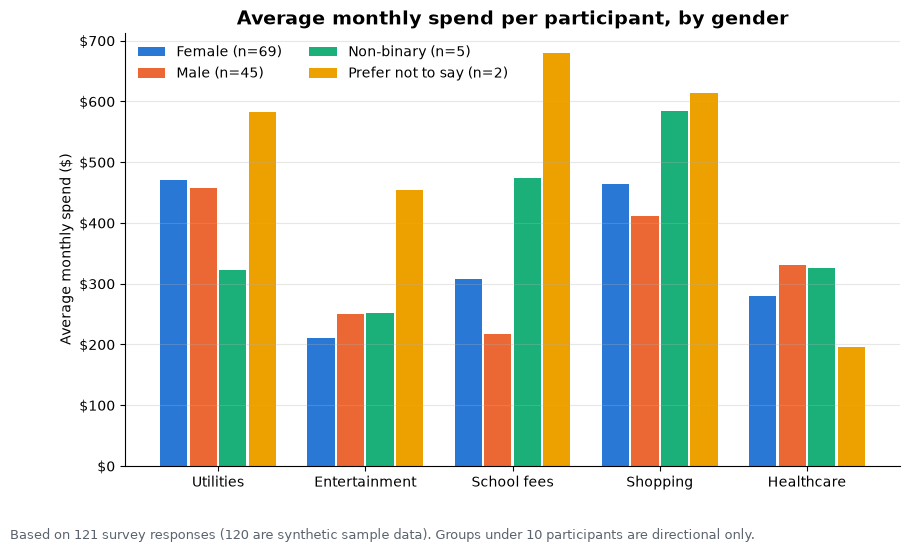

In [25]:
fig, ax = plt.subplots()
present = [g for g in GENDER_ORDER if group_sizes.get(g, 0) > 0]
width = 0.8 / len(present)
positions = range(len(CATEGORIES))
for i, gender in enumerate(present):
    offsets = [p - 0.4 + width * (i + 0.5) for p in positions]
    ax.bar(offsets, average_spend.loc[gender], width=width * 0.92, color=GENDER_COLORS[gender],
           label=f"{gender} (n={group_sizes[gender]})")
ax.set_xticks(list(positions), average_spend.columns)
ax.set(title="Average monthly spend per participant, by gender", ylabel="Average monthly spend ($)")
ax.yaxis.set_major_formatter(lambda value, _: f"${value:,.0f}")
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, ncol=2)
fig.text(0.01, -0.02, data_note(survey) + " Groups under 10 participants are directional only.",
         fontsize=9, color="#5b636e")
export_chart(fig, "average_spend_by_gender")
plt.show()

## Findings

> **Note:** these results come from **121 responses, 120 of which are synthetic sample data** generated by `seed_sample_data.py`. They demonstrate the analysis rather than real market behaviour. Re-run `export_to_csv.py` and this notebook once real responses are collected, or set `INCLUDE_SYNTHETIC = False`.

**Income by age**
- **45–54-year-olds have the highest average income** (about $7,270 a month), followed by 55–64 ($6,450) and 35–44 ($6,260).
- Income rises steeply from the 18–24 group ($2,760) and falls after 65 ($3,680).
- The **35–64 range** is the strongest-earning segment, and the natural primary audience for a paid healthcare product.

**Spending by gender**
- **Women account for over half of the spending in every category** (52–61%). That largely reflects their larger share of participants (69 of 121), not higher spending per person.
- **Per participant**, women and men spend similar amounts on utilities, and women spend somewhat more on shopping ($464 vs $412 a month).
- **Men spend more per person on healthcare** (about $330 vs $280 a month).
- The *Non-binary* (5) and *Prefer not to say* (2) groups are too small to draw conclusions from.

**Charts for the client presentation**, in `charts/` (16:9, 200 dpi):
- `income_by_age_group.png`
- `spending_share_by_gender.png`
- `average_spend_by_gender.png`